In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score, mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
actual = pd.read_csv('y_test_sel.csv')
predicted = pd.read_csv('ChatGPT_MIC_Predictions.csv')

In [3]:
y_pred = predicted['predicted_mic']

In [4]:
evaluation = pd.DataFrame([{
    'Model': 'GPT-6',
    'MAE': mean_absolute_error(actual, y_pred),
    'MSE': mean_squared_error(actual, y_pred),
    'RMSE': root_mean_squared_error(actual, y_pred),
    'R2': r2_score(actual, y_pred)
}])

print(evaluation)

   Model         MAE            MSE        RMSE        R2
0  GPT-6  102.109611  423809.610275  651.006613  0.334794


In [5]:
evaluation.to_csv('evaluation_gpt6_sel_MIC.csv', index=False)

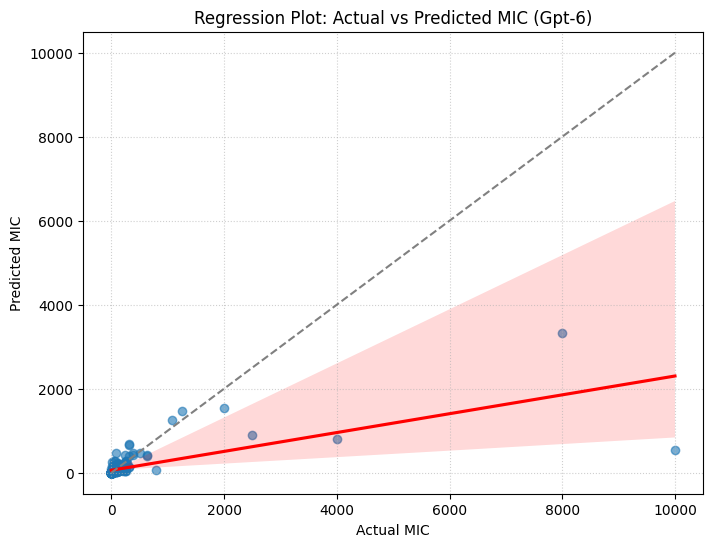

In [6]:
y_actual = actual.iloc[:, 0]

plt.figure(figsize=(8, 6))
sns.regplot(x=y_actual, y=y_pred, scatter_kws={'alpha':0.6}, line_kws={'color':'red'})

max_val = max(y_actual.max(), y_pred.max())
min_val = min(y_actual.min(), y_pred.min())
plt.plot([min_val, max_val], [min_val, max_val], color='gray', linestyle='--')

plt.xlabel('Actual MIC')
plt.ylabel('Predicted MIC')
plt.title('Regression Plot: Actual vs Predicted MIC (Gpt-6)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()